# Flower Classification with a Single Sigmoid Neuron

**Educational exercise — reproducible version of the uploaded `flowers.ipynb`.**\
Inputs: `length`, `width` → red/blue class labels (synthetic data). A single output neuron is **logistic regression**, not a multi-layer neural network. No separate test data is available.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
# Original eight classroom examples and mystery flower
DATA = np.array([[3.,1.5,1],[2.,1.,0],[4.,1.5,1],[3.,1.,0],
                 [3.5,.5,1],[2.,.5,0],[5.5,1.,1],[1.,1.,0]], dtype=float)
MYSTERY_FLOWER = np.array([4.5,1.0])
print('Number of labeled training samples:', len(DATA))

Number of labeled training samples: 8


## Model and training

`z = w₁·length + w₂·width + b` and `p = sigmoid(z)`. Train by minimizing mean binary cross-entropy with seeded full-batch gradient descent.

In [2]:
"""Reproducible educational binary flower classifier (single sigmoid neuron).

The eight labels are synthetic red/blue classes, not botanical species.
This is logistic regression, not a multi-hidden-layer neural network.
"""
from dataclasses import dataclass
import numpy as np

DATA = np.array([
    [3.0, 1.5, 1], [2.0, 1.0, 0], [4.0, 1.5, 1], [3.0, 1.0, 0],
    [3.5, 0.5, 1], [2.0, 0.5, 0], [5.5, 1.0, 1], [1.0, 1.0, 0],
], dtype=float)
MYSTERY_FLOWER = np.array([4.5, 1.0], dtype=float)


def sigmoid(z):
    """Numerically stable sigmoid, works on scalars and arrays."""
    x = np.asarray(z, dtype=float)
    ans = np.empty_like(x)
    positive = x >= 0
    ans[positive] = 1 / (1 + np.exp(-x[positive]))
    ez = np.exp(x[~positive])
    ans[~positive] = ez / (1 + ez)
    return float(ans) if ans.ndim == 0 else ans


def binary_cross_entropy_from_logits(logits, targets):
    """Mean binary cross-entropy computed stably in logit space."""
    z = np.asarray(logits, dtype=float)
    y = np.asarray(targets, dtype=float)
    return float(np.mean(np.logaddexp(0, z) - y * z))


@dataclass
class FlowerModel:
    weights: np.ndarray
    bias: float

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        return sigmoid(X @ self.weights + self.bias)

    def predict(self, X, threshold=0.5):
        return (np.asarray(self.predict_proba(X)) >= threshold).astype(int)


def train_model(data=DATA, *, seed=42, learning_rate=0.1, epochs=6000):
    """Full-batch gradient descent, a fixed RNG seed, and stable BCE loss.

    Returns (model, loss_history). This is demonstration-only training on 8
    labeled points; there is no independent generalization estimate.
    """
    matrix = np.asarray(data, dtype=float)
    if matrix.ndim != 2 or matrix.shape[1] != 3:
        raise ValueError('data must have columns [length, width, label]')
    if len(matrix) == 0 or not np.all(np.isin(matrix[:, 2], [0, 1])):
        raise ValueError('data must have at least one row with binary labels')
    if learning_rate <= 0 or epochs <= 0:
        raise ValueError('learning_rate and epochs must be positive')
    X, y = matrix[:, :2], matrix[:, 2]
    rng = np.random.default_rng(seed)
    w = rng.normal(0.0, 0.1, size=2)
    b = 0.0
    history = []
    for _ in range(epochs):
        logits = X @ w + b
        probabilities = sigmoid(logits)
        history.append(binary_cross_entropy_from_logits(logits, y))
        residuals = probabilities - y
        w -= learning_rate * (X.T @ residuals) / len(X)
        b -= learning_rate * float(np.mean(residuals))
    return FlowerModel(w, b), np.asarray(history)


In [3]:
model, losses = train_model(DATA, seed=42, learning_rate=0.1, epochs=6000)
X_train, y_train = DATA[:, :2], DATA[:, 2].astype(int)
train_predictions = model.predict(X_train)
train_accuracy = float(np.mean(train_predictions == y_train))
score = float(model.predict_proba(MYSTERY_FLOWER))
print(f'Initial BCE loss: {losses[0]:.6f}')
print(f'Final BCE loss: {losses[-1]:.6f}')
print(f'Training-set accuracy (8 points only): {train_accuracy:.3f}')
print(f'Mystery flower probability of red: {score:.6f}')
print('Mystery flower predicted class:', 'RED (1)' if score >= 0.5 else 'BLUE (0)')
assert losses[-1] < losses[0]
assert train_accuracy >= 0.75
assert 0 <= score <= 1

Initial BCE loss: 0.684722
Final BCE loss: 0.186946
Training-set accuracy (8 points only): 0.875
Mystery flower probability of red: 0.994671
Mystery flower predicted class: RED (1)


## Learning visualizations

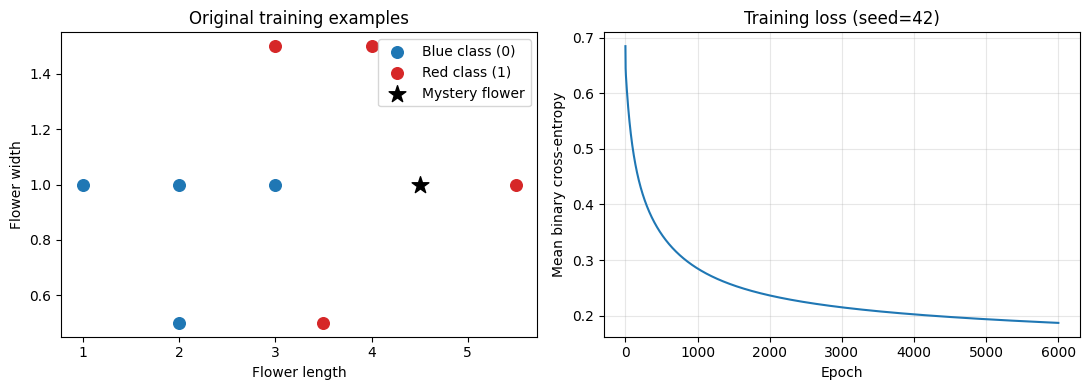

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for label, color, name in [(0, 'tab:blue', 'Blue class (0)'), (1, 'tab:red', 'Red class (1)')]:
    rows = DATA[DATA[:,2] == label]
    axes[0].scatter(rows[:,0], rows[:,1], c=color, label=name, s=70)
axes[0].scatter(*MYSTERY_FLOWER, marker='*', c='black', s=160, label='Mystery flower')
axes[0].set(xlabel='Flower length', ylabel='Flower width', title='Original training examples')
axes[0].legend()
axes[1].plot(losses)
axes[1].set(xlabel='Epoch', ylabel='Mean binary cross-entropy', title='Training loss (seed=42)')
axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

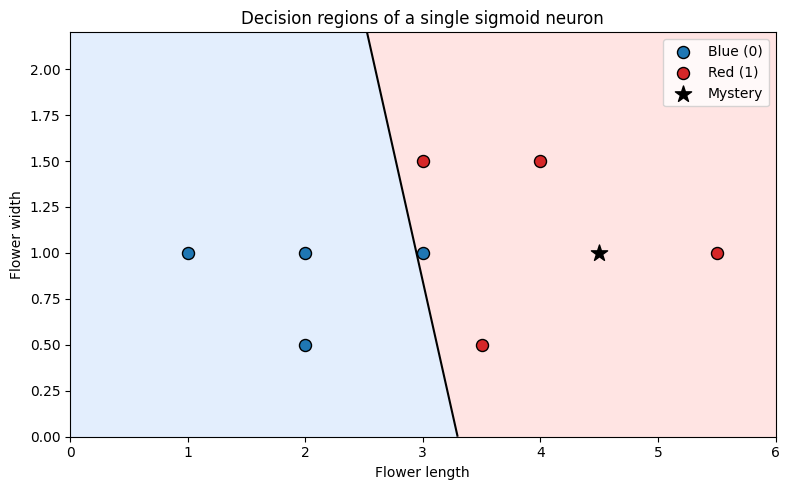

In [5]:
xx, yy = np.meshgrid(np.linspace(0, 6, 160), np.linspace(0, 2.2, 100))
features = np.column_stack([xx.ravel(), yy.ravel()])
zz = np.asarray(model.predict_proba(features)).reshape(xx.shape)
plt.figure(figsize=(8, 5))
plt.contourf(xx, yy, zz, levels=[0, .5, 1], colors=['#dae9fd','#ffdcda'], alpha=.75)
plt.contour(xx, yy, zz, levels=[.5], colors=['black'], linewidths=1.5)
for label, color, name in [(0, 'tab:blue', 'Blue (0)'), (1, 'tab:red', 'Red (1)')]:
    rows=DATA[DATA[:,2] == label]
    plt.scatter(rows[:,0], rows[:,1], c=color, edgecolors='black', label=name, s=75)
plt.scatter(*MYSTERY_FLOWER, marker='*', c='black', label='Mystery', s=150)
plt.xlabel('Flower length');plt.ylabel('Flower width')
plt.title('Decision regions of a single sigmoid neuron')
plt.legend();plt.tight_layout();plt.show()

## Interpretation and limitations

- This is a **single sigmoid neuron**; no hidden layers or flower-image recognition are implemented.
- Class 0 and Class 1 refer to **synthetic blue/red labels**, not botanical species.
- Accuracy printed above is on the **eight training examples only**; it is not test/validation accuracy.
- The original notebook's saved `0.991729...` mystery score came from an **unseeded** run; this updated BCE model does not claim to reproduce that score.
- More data and an independent holdout set are needed before generalization claims.

**Conclusion:** A two-feature linear classifier can learn a decision boundary via gradient descent. Numerical stability, repeatable training and proper interpretation of training metrics are essential for reliable experiments.